In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.metrics import roc_curve

In [28]:
df = pd.read_csv("/content/OnlineNewsPopularity.csv")

print("Dataset Loaded Successfully")
print("Dataset Shape:", df.shape)

df.head()

Dataset Loaded Successfully
Dataset Shape: (39644, 61)


,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


In [29]:
print("Dataset Information:")
df.info()

print("\nDataset Statistics:")
df.describe()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39644 entries, 0 to 39643
Data columns (total 61 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   url                             39644 non-null  object 
 1    timedelta                      39644 non-null  float64
 2    n_tokens_title                 39644 non-null  float64
 3    n_tokens_content               39644 non-null  float64
 4    n_unique_tokens                39644 non-null  float64
 5    n_non_stop_words               39644 non-null  float64
 6    n_non_stop_unique_tokens       39644 non-null  float64
 7    num_hrefs                      39644 non-null  float64
 8    num_self_hrefs                 39644 non-null  float64
 9    num_imgs                       39644 non-null  float64
 10   num_videos                     39644 non-null  float64
 11   average_token_length           39644 non-null  float64
 12   num_keywor

,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,num_videos,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
count,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,...,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000,39644.000000
mean,354.530471,10.398749,546.514731,0.548216,0.996469,0.689175,10.883690,3.293638,4.544143,1.249874,...,0.095446,0.756728,-0.259524,-0.521944,-0.107500,0.282353,0.071425,0.341843,0.156064,3395.380184
std,214.163767,2.114037,471.107508,3.520708,5.231231,3.264816,11.332017,3.855141,8.309434,4.107855,...,0.071315,0.247786,0.127726,0.290290,0.095373,0.324247,0.265450,0.188791,0.226294,11626.950749
min,8.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,-1.000000,-1.000000,-1.000000,0.000000,-1.000000,0.000000,0.000000,1.000000
25%,164.000000,9.000000,246.000000,0.470870,1.000000,0.625739,4.000000,1.000000,1.000000,0.000000,...,0.050000,0.600000,-0.328383,-0.700000,-0.125000,0.000000,0.000000,0.166667,0.000000,946.000000
50%,339.000000,10.000000,409.000000,0.539226,1.000000,0.690476,8.000000,3.000000,1.000000,0.000000,...,0.100000,0.800000,-0.253333,-0.500000,-0.100000,0.150000,0.000000,0.500000,0.000000,1400.000000
75%,542.000000,12.000000,716.000000,0.608696,1.000000,0.754630,14.000000,4.000000,4.000000,1.000000,...,0.100000,1.000000,-0.186905,-0.300000,-0.050000,0.500000,0.150000,0.500000,0.250000,2800.000000
max,731.000000,23.000000,8474.000000,701.000000,1042.000000,650.000000,304.000000,116.000000,128.000000,91.000000,...,1.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.500000,1.000000,843300.000000


In [30]:
print("Missing Values:")
print(df.isnull().sum().sum())

print("Duplicate Rows:")
print(df.duplicated().sum())

Missing Values:
0
Duplicate Rows:
0


In [31]:
df.columns = df.columns.str.strip()

df["popularity"] = (df["shares"] >= 1400).astype(int)

df[["shares", "popularity"]].head()

,shares,popularity
0,593,0
1,711,0
2,1500,1
3,1200,0
4,505,0


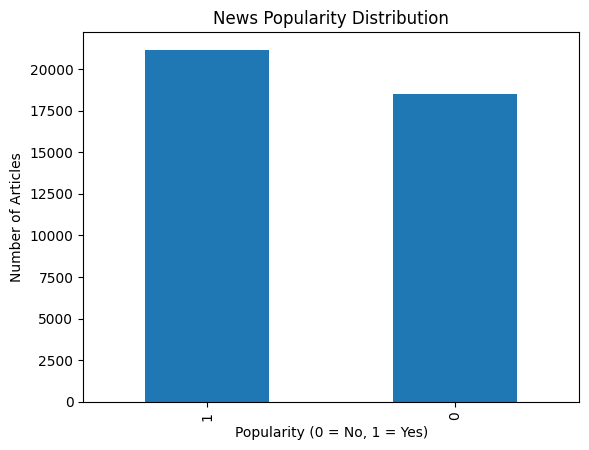

In [32]:
df["popularity"].value_counts().plot(kind="bar")

plt.title("News Popularity Distribution")
plt.xlabel("Popularity (0 = No, 1 = Yes)")
plt.ylabel("Number of Articles")
plt.show()

In [33]:
X = df.drop(["url", "shares", "popularity"], axis=1)
y = df["popularity"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (39644, 59)
Target Shape: (39644,)


In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (31715, 59)
Testing Data: (7929, 59)


In [35]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

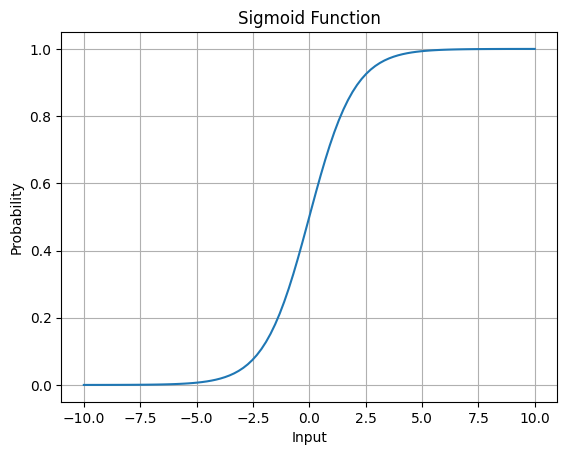

In [36]:
x = np.linspace(-10, 10, 100)
y = 1 / (1 + np.exp(-x))

plt.plot(x, y)
plt.title("Sigmoid Function")
plt.xlabel("Input")
plt.ylabel("Probability")
plt.grid()
plt.show()

In [37]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model Trained Successfully")

Model Trained Successfully


In [38]:
print("Intercept:", model.intercept_)

coefficients = pd.DataFrame({
    "Feature": df.drop(["url", "shares", "popularity"], axis=1).columns,
    "Coefficient": model.coef_[0]
})

coefficients.head(10)

Intercept: [0.1707003]


,Feature,Coefficient
0,timedelta,0.001150
1,n_tokens_title,0.000604
2,n_tokens_content,0.082267
3,n_unique_tokens,-0.006223
4,n_non_stop_words,0.077827
5,n_non_stop_unique_tokens,-0.043776
6,num_hrefs,0.118327
7,num_self_hrefs,-0.080024
8,num_imgs,0.023777
9,num_videos,-0.011526


In [39]:
probabilities = model.predict_proba(X_test)[:, 1]
predictions = model.predict(X_test)

result = pd.DataFrame({
    "Actual": y_test.values[:10],
    "Probability": probabilities[:10],
    "Predicted": predictions[:10]
})

result

,Actual,Probability,Predicted
0,0,0.263092,0
1,0,0.358876,0
2,0,0.430695,0
3,1,0.557589,1
4,1,0.838428,1
5,0,0.506236,1
6,1,0.511021,1
7,0,0.275890,0
8,0,0.266485,0
9,1,0.609192,1


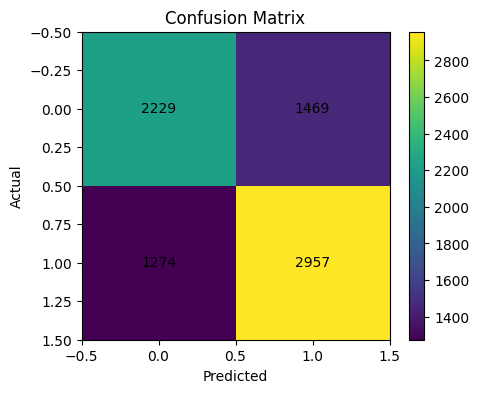

In [40]:
cm = confusion_matrix(y_test, predictions)

plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.show()

In [41]:
tn, fp, fn, tp = cm.ravel()

accuracy = accuracy_score(y_test, predictions)
precision = precision_score(y_test, predictions, zero_division=0)
recall = recall_score(y_test, predictions, zero_division=0)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, predictions, zero_division=0)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1 Score:", f1)

Accuracy: 0.6540547357800479
Precision: 0.6680976050610031
Recall: 0.6988891515008272
Specificity: 0.6027582477014602
F1 Score: 0.6831465865773363


In [42]:
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.64      0.60      0.62      3698
           1       0.67      0.70      0.68      4231

    accuracy                           0.65      7929
   macro avg       0.65      0.65      0.65      7929
weighted avg       0.65      0.65      0.65      7929



In [43]:
baseline = np.full(len(y_test), y_train.mode()[0])

print("Baseline Accuracy:", accuracy_score(y_test, baseline))
print("Model Accuracy:", accuracy)

Baseline Accuracy: 0.533610795812839
Model Accuracy: 0.6540547357800479


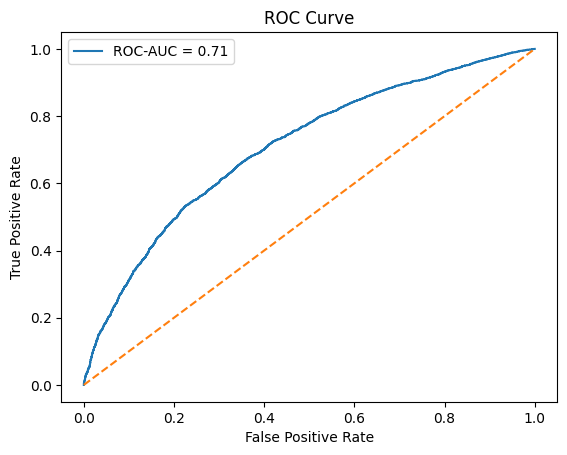

ROC-AUC: 0.707268545959738


In [44]:
auc = roc_auc_score(y_test, probabilities)

fpr, tpr, thresholds = roc_curve(y_test, probabilities)

plt.plot(fpr, tpr, label="ROC-AUC = %.2f" % auc)
plt.plot([0, 1], [0, 1], "--")

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

print("ROC-AUC:", auc)

In [45]:
for t in [0.3, 0.5, 0.7]:
    pred = (probabilities >= t).astype(int)

    print("\nThreshold:", t)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, zero_division=0))
    print("Recall:", recall_score(y_test, pred, zero_division=0))
    print("F1 Score:", f1_score(y_test, pred, zero_division=0))


Threshold: 0.3
Accuracy: 0.5795182242401312
Precision: 0.5628063296457079
Recall: 0.9498936421649729
F1 Score: 0.7068237776996131

Threshold: 0.5
Accuracy: 0.6540547357800479
Precision: 0.6680976050610031
Recall: 0.6988891515008272
F1 Score: 0.6831465865773363

Threshold: 0.7
Accuracy: 0.5805271787110606
Precision: 0.7884002549394519
Recall: 0.2923658709524935
F1 Score: 0.426551724137931


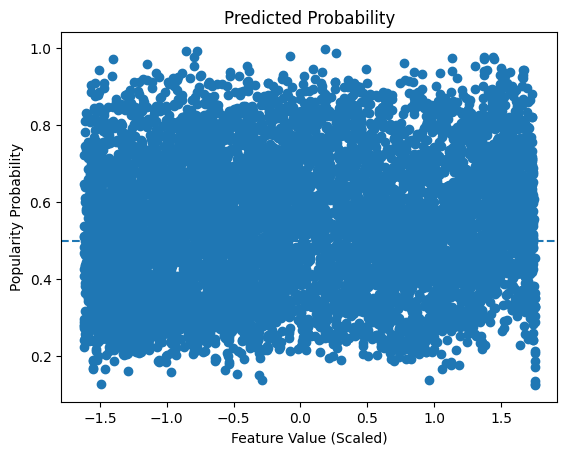

In [46]:
plt.scatter(X_test[:, 0], probabilities)

plt.axhline(0.5, linestyle="--")
plt.title("Predicted Probability")
plt.xlabel("Feature Value (Scaled)")
plt.ylabel("Popularity Probability")
plt.show()

In [47]:
new_data = X_test[0:1]

probability = model.predict_proba(new_data)[0][1]
prediction = model.predict(new_data)[0]

print("Popularity Probability:", probability)
print("Prediction:", "Popular" if prediction == 1 else "Not Popular")

Popularity Probability: 0.26309151394009095
Prediction: Not Popular
